# Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncoverinsights that can inform business strategies and decision-making.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

sns.set_style("whitegrid")
%matplotlib inline

### Load the data

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
print(df.shape)
df.head()

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Data-cleaning noteAs in Part I, `stars == 0` (together with `reviews == 0`) marks products that have neverbeen reviewed rather than a genuine 0-star rating. We treat those as missing so they don'tdistort any rating-based statistic below.

In [3]:
df['stars'] = df['stars'].replace(0, np.nan)
print(f"Products with no rating yet: {df['stars'].isna().sum():,} ({df['stars'].isna().mean():.1%})")

Products with no rating yet: 1,225,641 (50.2%)


## Part 1: Analyzing Best-Seller Trends Across Product Categories**Objective**: Understand the relationship between product categories and their best-seller status.

#### 1. Crosstab analysis

In [4]:
bestseller_crosstab = pd.crosstab(df['category'], df['isBestSeller'])
bestseller_crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


Proportion of best-sellers per category, sorted descending:

In [5]:
bestseller_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
bestseller_prop_sorted = bestseller_prop.sort_values(by=True, ascending=False)
bestseller_prop_sorted.head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


#### 2. Statistical tests

In [6]:
chi2, p_value, dof, expected = chi2_contingency(bestseller_crosstab)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.4g}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 36540.20
p-value: 0
Degrees of freedom: 295


In [7]:
n = bestseller_crosstab.sum().sum()
r, k = bestseller_crosstab.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.1223


#### 3. Visualization

With 296 categories, a stacked bar chart of all of them is unreadable, so we plot the top 20 categories by listing count.

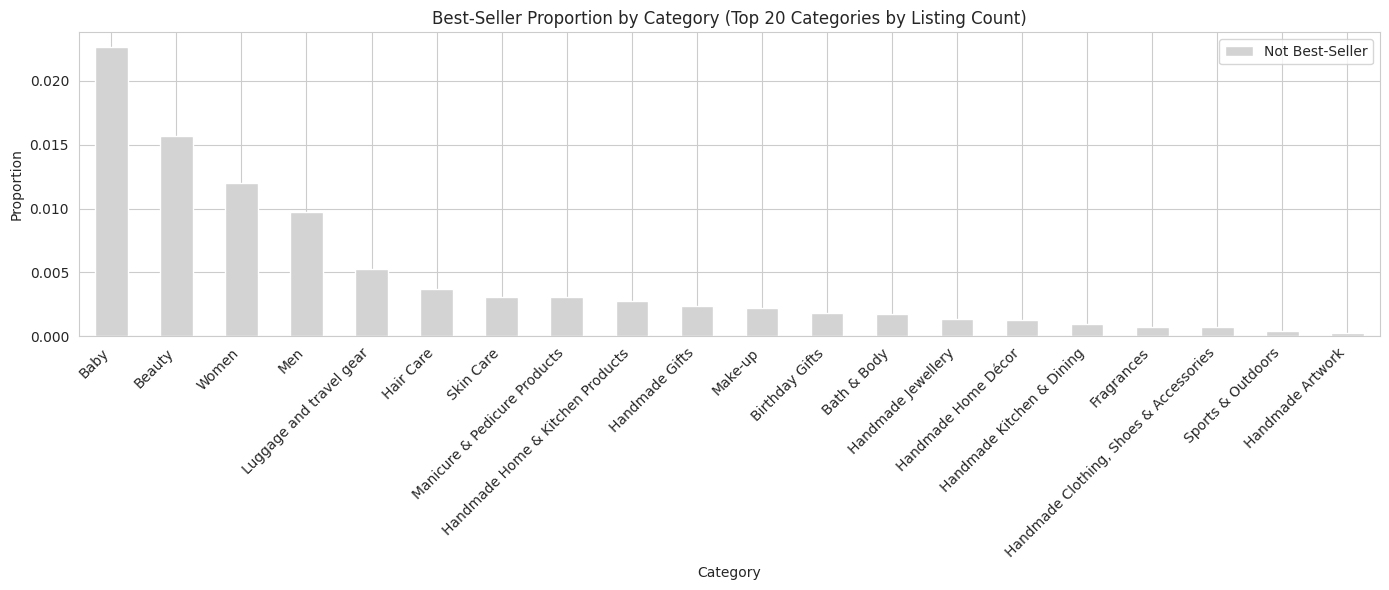

In [8]:
top_categories = df['category'].value_counts().head(20).index

plot_data = bestseller_prop.loc[top_categories, [False, True]]
plot_data = plot_data.loc[plot_data[True].sort_values(ascending=False).index]

plot_data.plot(kind='bar', stacked=True, figsize=(14, 6), color=['lightgray', 'crimson'])
plt.title('Best-Seller Proportion by Category (Top 20 Categories by Listing Count)')
plt.xlabel('Category')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(['Not Best-Seller', 'Best-Seller'])
plt.tight_layout()
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands**Objective**: Investigate how different product categories influence product prices.

#### 0. Preliminary step: remove price outliers (IQR method)

In [9]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Lower bound: £{lower_bound:.2f}, Upper bound: £{upper_bound:.2f}")
print(f"Rows before: {len(df):,}")
print(f"Rows after:  {len(df_no_outliers):,}")
print(f"Removed:     {len(df) - len(df_no_outliers):,} ({(len(df)-len(df_no_outliers))/len(df):.1%})")

Lower bound: £-44.01, Upper bound: £99.99
Rows before: 2,443,651
Rows after:  2,115,963
Removed:     327,688 (13.4%)


_From here on, Part 2 and Part 3 use `df_no_outliers` unless stated otherwise._

#### 1. Violin plots - price by category

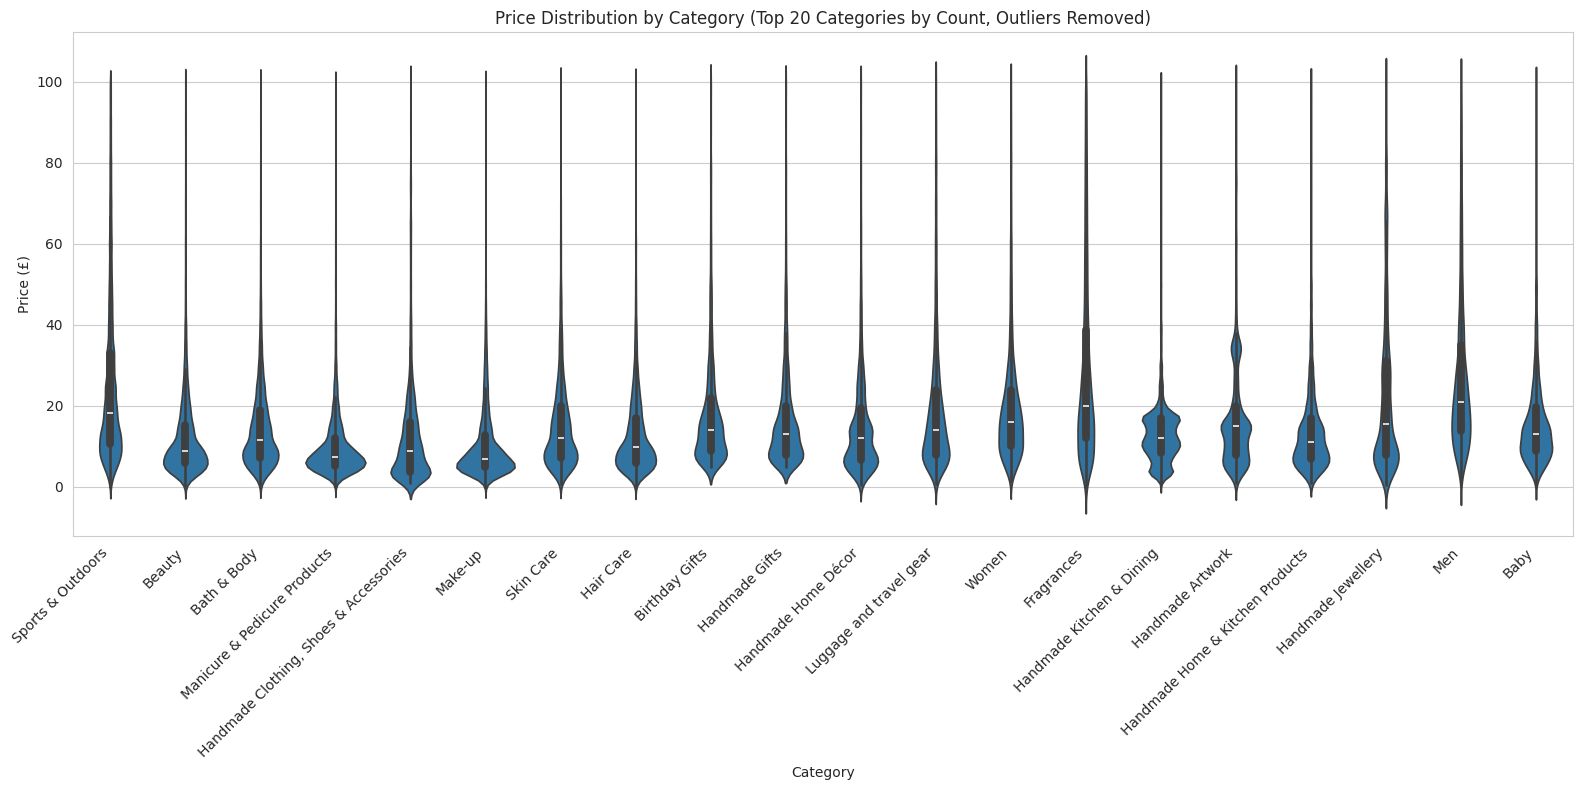

In [10]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index
violin_data = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]

plt.figure(figsize=(16, 8))
sns.violinplot(data=violin_data, x='category', y='price', order=top_20_categories)
plt.title('Price Distribution by Category (Top 20 Categories by Count, Outliers Removed)')
plt.xlabel('Category')
plt.ylabel('Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Highest median price category, **without** filtering to top categories:

In [11]:
median_price_by_category = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

#### 2. Bar chart - average price, top 10 categories by count

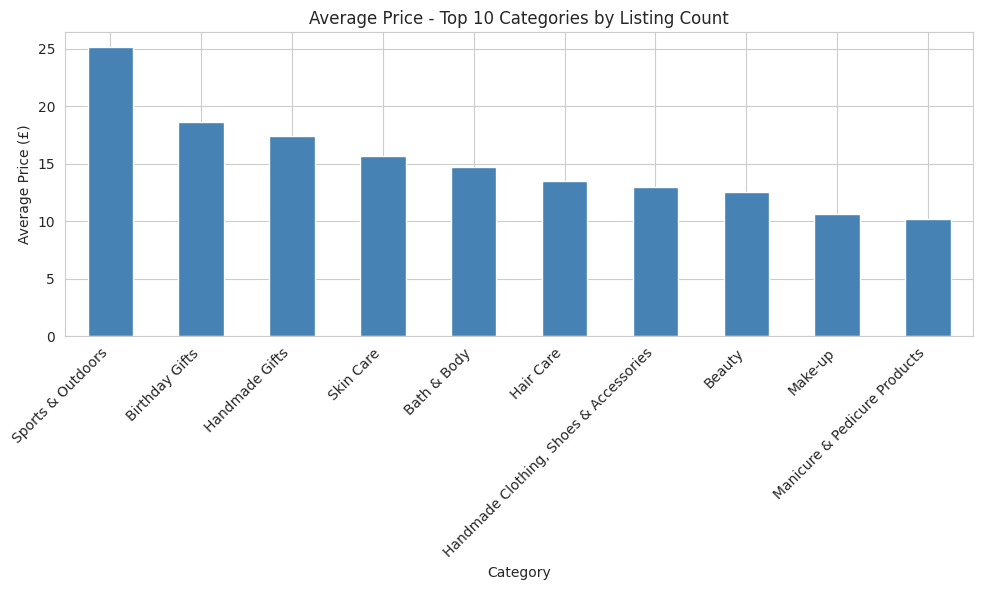

In [12]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index
avg_price_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
avg_price_top10.plot(kind='bar', color='steelblue')
plt.title('Average Price - Top 10 Categories by Listing Count')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Highest average price category, **without** filtering to top categories:

In [13]:
avg_price_by_category = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price_by_category.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

#### 3. Box plots - ratings by category, top 10 categories by count

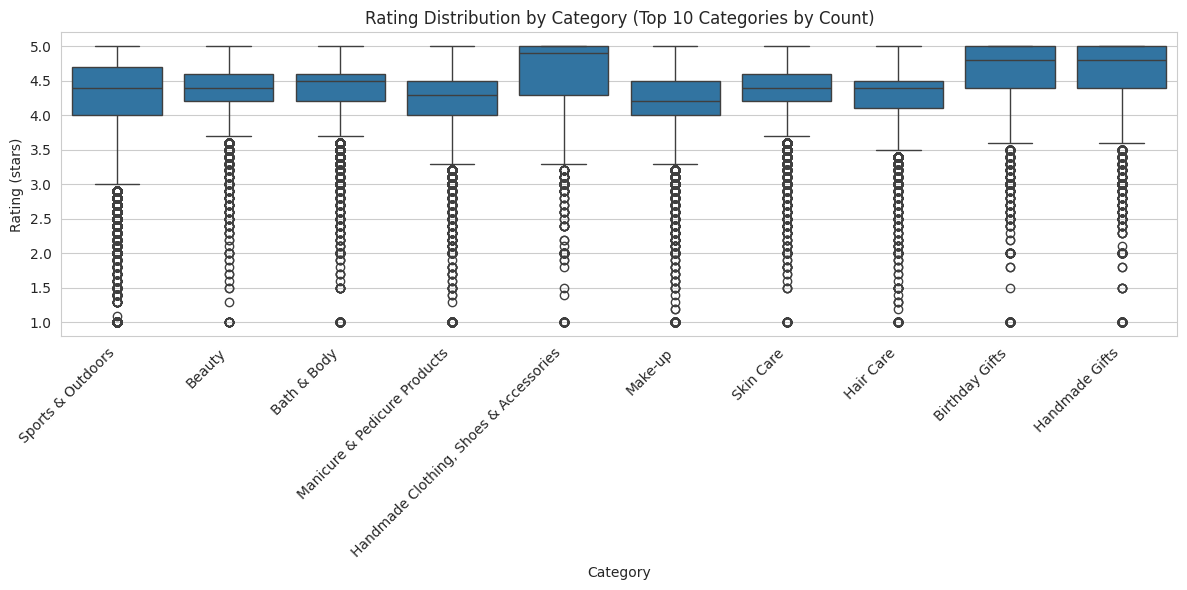

In [14]:
box_data = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=box_data, x='category', y='stars', order=top_10_categories)
plt.title('Rating Distribution by Category (Top 10 Categories by Count)')
plt.xlabel('Category')
plt.ylabel('Rating (stars)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Highest median rating category, **without** filtering to top categories:

In [15]:
median_rating_by_category = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_rating_by_category.head(10)

category
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Artwork                          5.0
Handmade Kitchen & Dining                 4.9
Handmade Clothing, Shoes & Accessories    4.9
Birthday Gifts                            4.8
Handmade Gifts                            4.8
Handmade Home Décor                       4.8
Handmade Home & Kitchen Products          4.7
Computer Memory                           4.7
Name: stars, dtype: float64

## Part 3: Investigating the Interplay Between Product Prices and Ratings**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

#### 1. Correlation coefficient

In [16]:
rated = df_no_outliers.dropna(subset=['stars'])

pearson_r, pearson_p = stats.pearsonr(rated['price'], rated['stars'])
print(f"Pearson correlation (price, stars): r = {pearson_r:.4f}, p-value = {pearson_p:.4g}")

Pearson correlation (price, stars): r = 0.0067, p-value = 1.081e-12


#### 2. Visualizations

A scatter plot of ~2M points is unreadable and slow to render, so we plot a random sample.

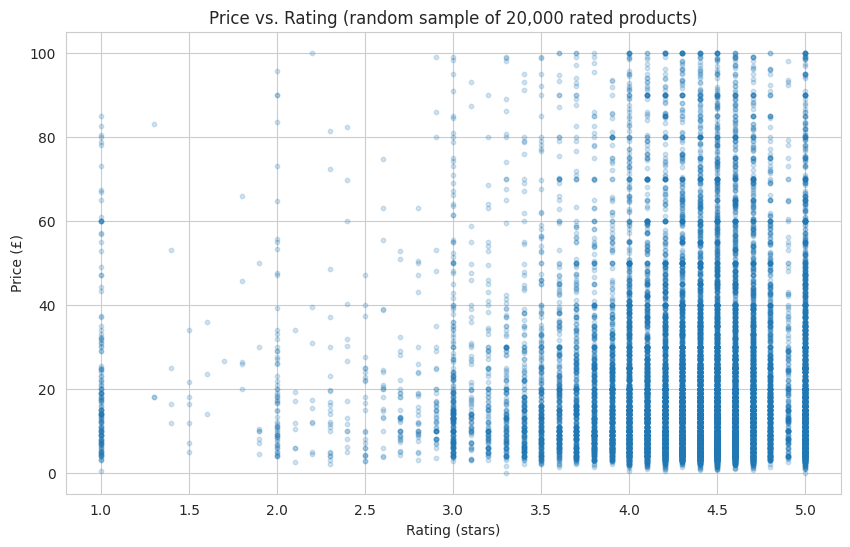

In [17]:
sample = rated.sample(n=20000, random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sample['stars'], sample['price'], alpha=0.2, s=10)
plt.title('Price vs. Rating (random sample of 20,000 rated products)')
plt.xlabel('Rating (stars)')
plt.ylabel('Price (£)')
plt.show()

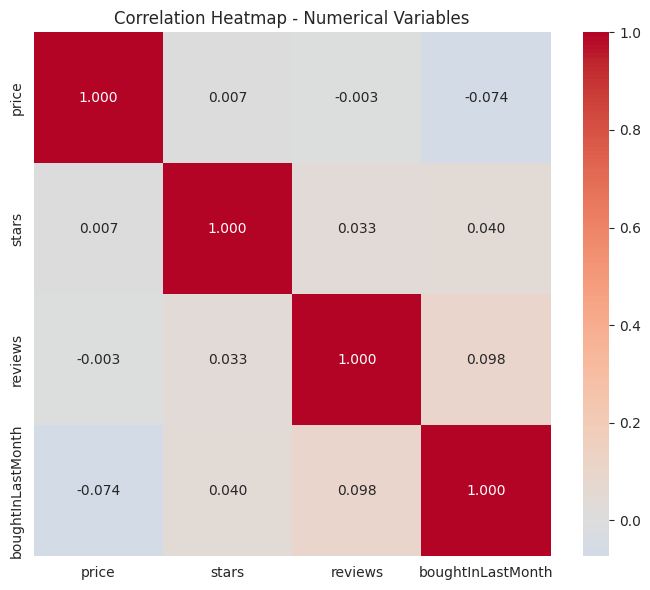

In [18]:
numerical_cols = ['price', 'stars', 'reviews', 'boughtInLastMonth']
corr_matrix = rated[numerical_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.3f')
plt.title('Correlation Heatmap - Numerical Variables')
plt.tight_layout()
plt.show()

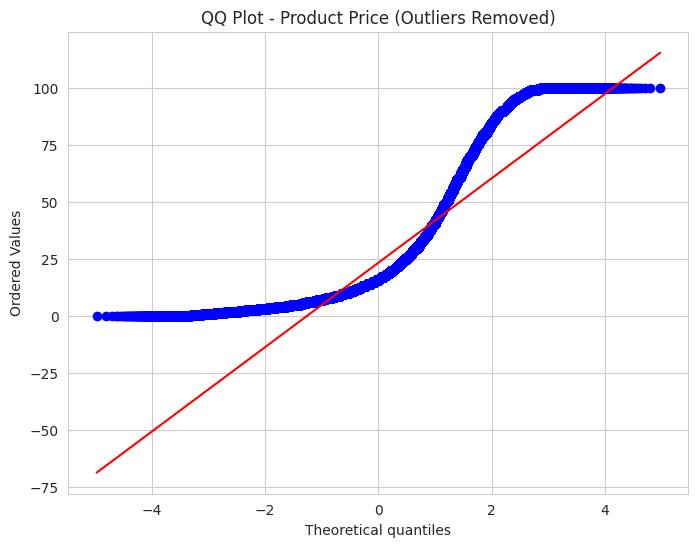

In [19]:
plt.figure(figsize=(8, 6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot - Product Price (Outliers Removed)')
plt.show()

## Bonus: Same Analysis Without Removing Outliers

In [20]:
avg_price_by_category_full = df.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price_by_category_full.head(10)

category
Laptops                       1087.987827
3D Printers                   1018.036129
Desktop PCs                    926.816064
Home Office Furniture          622.135898
Test & Measurement             559.382973
Home Audio Record Players      529.665585
CPUs                           514.519317
Digital Cameras                496.156185
Material Handling Products     487.191813
Graphics Cards                 444.746827
Name: price, dtype: float64

In [21]:
rated_full = df.dropna(subset=['stars'])
pearson_r_full, pearson_p_full = stats.pearsonr(rated_full['price'], rated_full['stars'])
print(f"Pearson correlation with outliers included: r = {pearson_r_full:.4f}, p-value = {pearson_p_full:.4g}")

Pearson correlation with outliers included: r = -0.0049, p-value = 5.93e-08


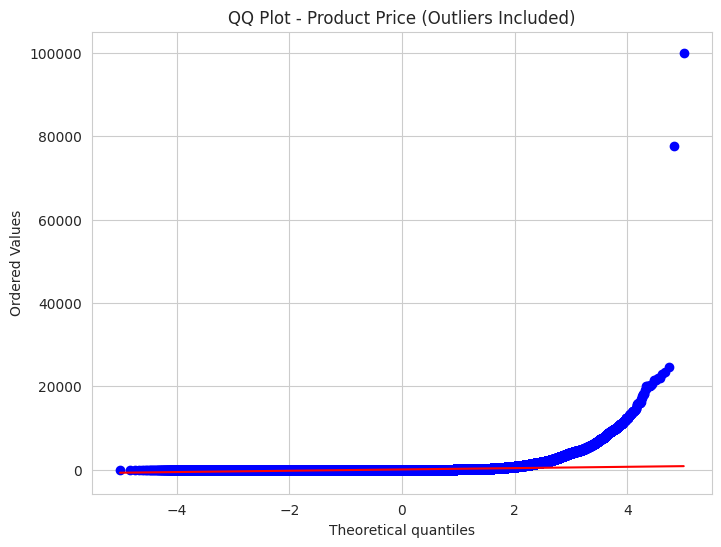

In [22]:
plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title('QQ Plot - Product Price (Outliers Included)')
plt.show()

_Insight: compare the top-price categories, correlation, and QQ plot shape above to their outlier-removed versions -- note how a handful of very expensive products change the picture._

---## Business-Centric Summary- **Best-seller status is statistically linked to category, but only weakly in practice.**  The chi-square test is highly significant (p ≈ 0), but with 2.44M rows almost anything  is "significant" -- the more meaningful number is Cramér's V = **0.12**, indicating a  *weak* real-world association. Even the category with the highest best-seller rate  (Grocery) only reaches **5.8%**, and best-sellers overall are extremely rare  (7,980 out of 2,443,651 listings, 0.33%). Category alone is not a strong lever for  predicting best-seller status.- **Outlier removal matters a lot for pricing conclusions.** The IQR method flags anything  above **£99.99** as an outlier, removing **13.4%** of all listings (327,688 products) --  including essentially all higher-end electronics. This flips which categories look  "expensive": without outliers, commodity computer parts top the list (Motherboards  £68.77, Desktop PCs £74.00 median); *with* outliers included, big-ticket electronics  dominate instead (Laptops £1,087.99, 3D Printers £1,018.04, Desktop PCs £926.82 average).  Which version is "correct" depends on the business question -- typical basket pricing  vs. high-value inventory planning need different treatments of these outliers.- **Price and rating are essentially uncorrelated** (Pearson r = 0.0067 without outliers,  r = -0.0049 with outliers -- both technically "significant" only because of the huge  sample size, but both practically zero). Customers do not rate expensive products  systematically higher or lower than cheap ones on this platform -- price is not a proxy  for perceived quality here.- **The highest-rated categories are dominated by niche/handmade goods** (Made in Italy  Handmade, Handmade Baby Products, Handmade Artwork, all median 5.0 stars) rather than  mainstream categories, suggesting these smaller, curated product lines earn outsized  customer satisfaction relative to their sales volume.